# Regresión lineal para predicción de progresión de diabetes
- age: Representa la edad del paciente, normalizada (no es la edad real, sino una representación estandarizada).
- sex: Sexo del paciente, representado como una variable numérica normalizada (valores entre -0.5 y 0.5).
- bmi: Índice de Masa Corporal (Body Mass Index, BMI), una medida del peso relativo al cuadrado de la altura.
- bp:
Promedio de presión arterial (Blood Pressure, BP), normalizada.
- s1: Nivel sérico de lípidos totales (colesterol total).
- s2: Nivel sérico de lipoproteínas de baja densidad (LDL, “colesterol malo”).
- s3: Nivel sérico de lipoproteínas de alta densidad (HDL, “colesterol bueno”).
- s4: Relación entre el colesterol total y HDL.
- s5: Nivel sérico de triglicéridos, representado como una medida numérica normalizada.
- s6: Nivel sérico de glucosa en ayuno, una medida clave en el monitoreo de la diabetes.

In [1]:
# Importar las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

# Cargar el conjunto de datos
diabetes_data = load_diabetes()

# Convertir el conjunto de datos a un DataFrame para facilitar su manipulación
df = pd.DataFrame(data=diabetes_data.data, columns=diabetes_data.feature_names)
df['target'] = diabetes_data.target  # Agregar la variable objetivo al DataFrame

# Mostrar las primeras filas del DataFrame
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 1. EXPLORACION

In [2]:
print(df.shape)
print("Valores faltantes:", df.isnull().sum().sum())
print(df.describe().round(3))

# Correlación de cada variable con el objetivo
print(df.corr()['target'].drop('target').sort_values(ascending=False).round(2))

(442, 11)
Valores faltantes: 0
           age      sex      bmi       bp       s1       s2       s3       s4  \
count  442.000  442.000  442.000  442.000  442.000  442.000  442.000  442.000   
mean    -0.000    0.000   -0.000   -0.000   -0.000    0.000   -0.000   -0.000   
std      0.048    0.048    0.048    0.048    0.048    0.048    0.048    0.048   
min     -0.107   -0.045   -0.090   -0.112   -0.127   -0.116   -0.102   -0.076   
25%     -0.037   -0.045   -0.034   -0.037   -0.034   -0.030   -0.035   -0.039   
50%      0.005   -0.045   -0.007   -0.006   -0.004   -0.004   -0.007   -0.003   
75%      0.038    0.051    0.031    0.036    0.028    0.030    0.029    0.034   
max      0.111    0.051    0.171    0.132    0.154    0.199    0.181    0.185   

            s5       s6   target  
count  442.000  442.000  442.000  
mean     0.000    0.000  152.133  
std      0.048    0.048   77.093  
min     -0.126   -0.138   25.000  
25%     -0.033   -0.033   87.000  
50%     -0.002   -0.001  140.

El conjunto tiene 442 pacientes, 10 variables predictoras y 1 objetivo, sin valores faltantes. Las variables más correlacionadas con la progresión de la enfermedad son bmi (0.59) y s5 (0.57). s3 es la única con relación negativa notable (-0.39).

## 2. PREPROCESAMIENTO: separar y escalar

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# El escalador se ajusta solo con entrenamiento
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(X_train.shape, X_test.shape)

(353, 10) (89, 10)


Se separó 80% para entrenar y 20% para probar. 353 pacientes que se alimentan como aprendizaje al modelo; 89 pacientes que el modelo nunca vió y que se guardan para evaluar la predicción.

El escalador se ajustó solo con los datos de entrenamiento, para que el conjunto de prueba no influya en el modelo. 

Las variables de este dataset ya vienen normalizadas, así que el escalado cambia poco, pero se aplica para seguir el ciclo completo.

## 3. ENTRENAMIENTO

In [6]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression()
modelo.fit(X_train_s, y_train)

coeficientes = pd.Series(modelo.coef_, index=X.columns).sort_values()
print(coeficientes.round(1))
print("Intercepto:", round(modelo.intercept_, 1))

s1    -44.4
sex   -11.5
age     1.8
s6      2.4
s3      7.7
s4     13.1
bp     16.8
s2     24.6
bmi    25.6
s5     35.2
dtype: float64
Intercepto: 153.7


Las variables con mayor peso positivo son s5 (35.2), bmi (25.6) y s2 (24.6). 

s1 pesa -44.4, el mayor efecto negativo. 

s1 y s2 están muy correlacionadas entre sí, y por eso sus coeficientes son grandes y de signo opuesto; conviene no interpretarlos por separado.

Como las variables están estandarizadas, un coeficiente de 25.6 en bmi indica que, manteniendo lo demás constante, un aumento de una desviación estándar en bmi se asocia con unos 26 puntos más de progresión

## 4. EVALUACION

In [7]:
from sklearn.metrics import mean_squared_error, r2_score

y_pred = modelo.predict(X_test_s)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RMSE:", round(rmse, 2))
print("R² prueba:", round(r2, 3))
print("R² entrenamiento:", round(modelo.score(X_train_s, y_train), 3))

RMSE: 53.85
R² prueba: 0.453
R² entrenamiento: 0.528


El modelo obtuvo un RMSE de 53.85 y un R² de 0.45 en prueba.

Es decir, explica cerca de la mitad de la variabilidad de la progresión de la diabetes. Como el objetivo tiene una desviación estándar de 77, el error típico de 54 es moderado: el modelo aporta información, pero no es muy preciso. 

El R² de entrenamiento (0.53) es similar al de prueba, así que no hay sobreajuste importante.

## 5. Gráfica de predicciones vs. valores reales

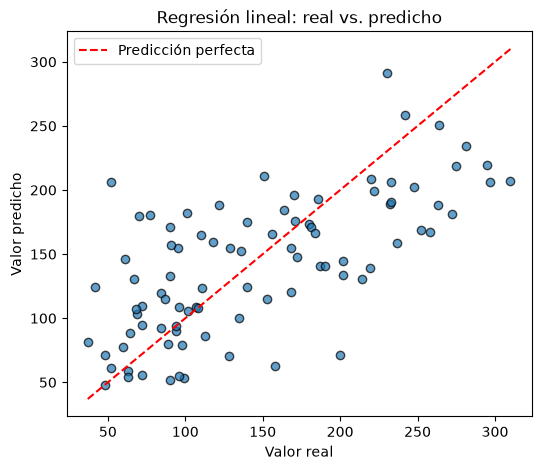

In [8]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.7, edgecolor='black')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Predicción perfecta')
plt.xlabel('Valor real')
plt.ylabel('Valor predicho')
plt.title('Regresión lineal: real vs. predicho')
plt.legend()
plt.show()

- Con valores reales altos (más de 200), el modelo tiende a subestimar. La mayoría de los puntos de la derecha quedan por debajo de la línea roja. Por ejemplo, pacientes con valor real cercano a 300 reciben predicciones de alrededor de 200.

- Con valores reales bajos (menos de 100), el modelo tiende a sobreestimar. Hay puntos por encima de la línea, como uno con valor real cercano a 50 y predicción de 205.

- Hay dispersión amplia en general. Esto concuerda con el R² de 0.45 y el RMSE de 53.85.

El objetivo era predecir la progresión de la diabetes un año después usando datos médicos de los pacientes. Para eso se entrenó un modelo de regresión lineal con 353 pacientes y se probó con 89 que no había visto.

Los factores que más pesan en la progresión son s5, bmi y bp. Entre más altos son estos valores, mayor es la progresión de la enfermedad.

El modelo captura la tendencia general, pero subestima a los pacientes con progresión alta y sobreestima a los de progresión baja. Esto indica que las 10 variables disponibles, con un modelo lineal, no alcanzan a explicar los casos extremos. Sirve para ver la tendencia general, pero no es muy preciso en cada paciente, sobre todo en los casos extremos. Como no hay sobreajuste, un modelo más flexible podría mejorarlo.